## Messages in LangGraph 


"Messages in LangGraph represent the conversation between users, AI models, and tools. They are maintained in the graph state and allow different nodes to access and update the conversation history."

Simple language mein:

Jab hum chatbot ya AI Agent banate hain, toh conversation mein multiple messages hote hain:
- Human message – User ka question.
- AI message – LLM ka response.
- Tool message – Tool ke execution ka result.
- System message – AI ke behaviour ke instructions.
LangGraph mein hum in messages ko State ke andar maintain kar sakte hain.

In [15]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Sure! Did you know that India is home to the world’s largest **family‑run business**? The **Tata Group**, founded in 1868, started as a small trading firm and has grown into a multinational conglomerate spanning steel, automobiles, IT services, hospitality, and more—employing over 800,000 people worldwide while still being largely controlled by the Tata family. 🌏🚂✨


In [16]:
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
    SystemMessage,
    ToolMessage
)

## Messages ko State mein kaise maintain karte hain?

Abhi tak hum State mein simple strings use kar rahe the:

Lekin chatbot banate waqt har baar message overwrite karna useful nahi hoga.

Humein complete conversation history maintain karni hai.

Isliye hum messages key use karte hain.



In [17]:
from typing import TypedDict
from langchain_core.messages import AnyMessage
#AnyMessage ka simple meaning hai: kisi bhi type ka LangChain message.

class GraphState(TypedDict):
    messages: list[AnyMessage]
# Ab iska meaning samjho:
# - messages ek list hai.
# - List ke andar HumanMessage aa sakta hai.
# - AIMessage aa sakta hai.
# - SystemMessage aa sakta hai.
# - ToolMessage aa sakta hai.

# Matlab tumhe alag-alag message types ke liye alag lists banane ki zarurat nahi.

# Ek line mein yaad rakhna:

# AnyMessage is a general message type that allows different kinds of LangChain messages to exist in the same list or state.


# Abb state aisa Dikega :

# {
#     "messages": [
#         HumanMessage(content="Hi"),
#         AIMessage(content="Hello!"),
#         HumanMessage(content="What is LangGraph?")
#     ]
# }

## MessagesState kya hota hai?
LangGraph already ek predefined state provide karta hai: MessagesState.

from langgraph.graph import MessagesState



Instead of manually writing:
class GraphState(TypedDict):    messages: list[AnyMessage]


We can simply write:
class GraphState(MessagesState):    name: str

MessagesState already provides a messages field and uses the add_messages reducer.
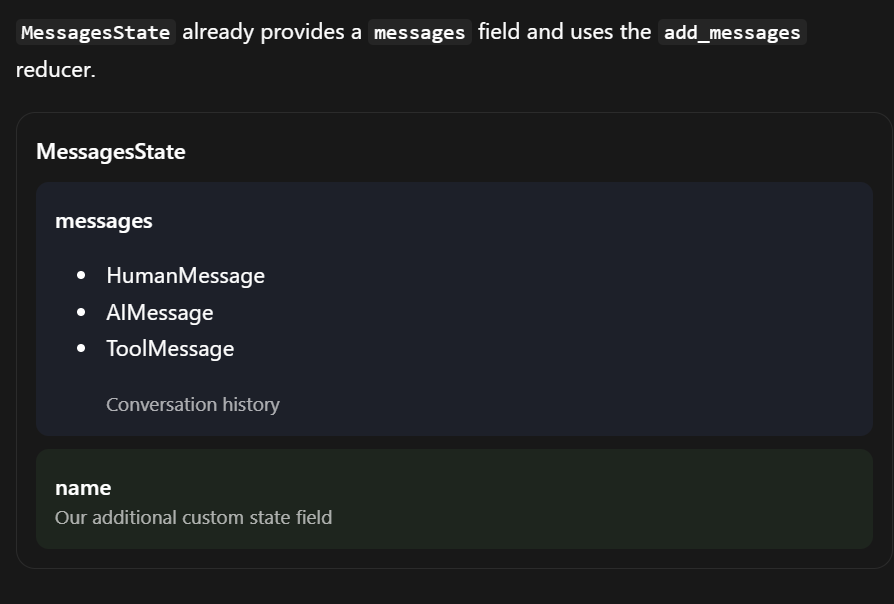

Normally, agar hum same State key update karte hain, toh default behavior mein purani value replace hoti hai.

But messages ke case mein humein purani conversation delete nahi karni.
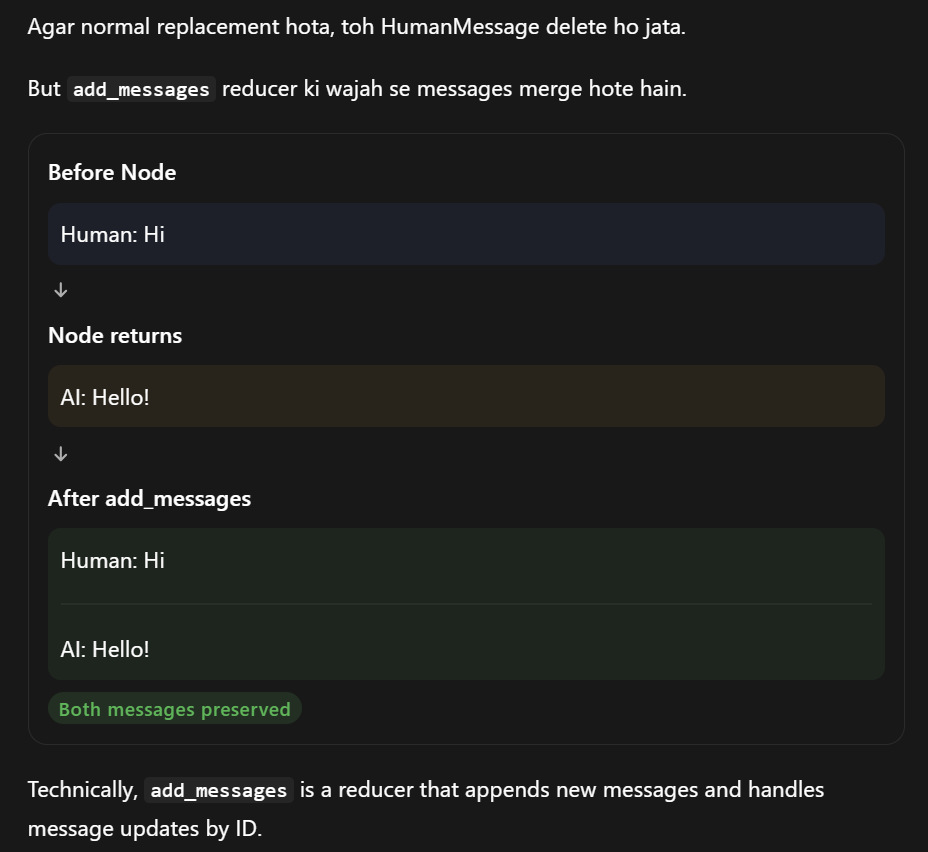

## Step 1 : Define the GraphState

In [18]:
from langgraph.graph import MessagesState

class GraphState(MessagesState):
    pass

## Step 2 : Define the Node functions 

In [19]:
def chatbot(state: GraphState):

    response = llm.invoke(state["messages"])

    return {
        "messages": [response]
    }


#     Yahan:
# - state["messages"] = Complete conversation history.
# - llm.invoke() = LLM ko conversation bhejna.
# - [response] = New AI message.
# - add_messages = Existing history mein new response add karna.

## Step 3 : Create the State Graph

In [20]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(GraphState)

builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile(
    
)

## Step 4 : Invoke the Graph

In [23]:
from langchain_core.messages import HumanMessage,SystemMessage

result = graph.invoke({
    "messages": [
        SystemMessage(content="You are a Helpful Ai assistenat"),
        HumanMessage(content="Hi, my name is Rahul.")
    ]
})

print(result["messages"][-1].content
)

Hello Rahul! 👋 Nice to meet you. How can I assist you today?
